In [1]:
import requests, pandas as pd
r = requests.get("https://data.humdata.org/api/3/action/package_show",
                 params={"id": "nga-rainfall-subnational"}, timeout=60)
print("Status:", r.status_code)
d = r.json()["result"]
print(d["title"], "|", d.get("license_title"), "| last updated:", d.get("last_modified", "")[:10])
for res in d["resources"]:
    print("-", res["name"], "|", res["url"])

Status: 200
Nigeria: Rainfall Indicators at Subnational Level | Creative Commons Attribution International (CC BY) | last updated: 2026-11-03
- nga-rainfall-subnat-full.csv | https://data.humdata.org/dataset/ff5dba07-397b-44fb-b04f-bbca782ce793/resource/114874de-df99-4102-b4c8-b44e2db44a5e/download/nga-rainfall-subnat-full.csv
- nga-rainfall-subnat-5ytd.csv | https://data.humdata.org/dataset/ff5dba07-397b-44fb-b04f-bbca782ce793/resource/2670aa7f-21c1-4ebc-88d6-8d99683e5a60/download/nga-rainfall-subnat-5ytd.csv


In [2]:
url = next(res["url"] for res in d["resources"] if "full" in res["url"].lower())
rain = pd.read_csv(url, low_memory=False)
print(url.split("/")[-1], rain.shape)
print("\nColumns:", rain.columns.tolist())
print("\n", rain.head(3).to_string())

date_col = next(c for c in rain.columns if "date" in c.lower())
print("\nDates from", rain[date_col].min(), "to", rain[date_col].max())
for c in rain.columns:
    if "level" in c.lower() or "name" in c.lower() or "pcode" in c.lower() or c.lower().endswith("_id"):
        print(f"\n{c}: {rain[c].nunique()} distinct values, e.g. {rain[c].dropna().unique()[:6].tolist()}")

nga-rainfall-subnat-full.csv (1321650, 15)

Columns: ['date', 'adm_level', 'adm_id', 'PCODE', 'n_pixels', 'rfh', 'rfh_avg', 'r1h', 'r1h_avg', 'r3h', 'r3h_avg', 'rfq', 'r1q', 'r3q', 'version']

          date  adm_level  adm_id  PCODE  n_pixels        rfh    rfh_avg        r1h   r1h_avg  r3h  r3h_avg         rfq         r1q  r3q version
0  1981-01-01          1   65698  NG001     155.0  14.212903   5.789033        NaN       NaN  NaN      NaN  178.078100         NaN  NaN   final
1  1981-01-11          1   65698  NG001     155.0   3.554839   5.517419        NaN       NaN  NaN      NaN   81.339710         NaN  NaN   final
2  1981-01-21          1   65698  NG001     155.0  10.135484  10.415699  27.903225  21.72215  NaN      NaN   98.182274  123.130905  NaN   final

Dates from 1981-01-01 to 2026-10-21

adm_level: 2 distinct values, e.g. [1, 2]

adm_id: 801 distinct values, e.g. [65698, 65699, 65700, 65701, 65702, 65703]

PCODE: 788 distinct values, e.g. ['NG001', 'NG005', 'NG006', 'NG011', '

In [3]:
adm1 = rain[rain.adm_level == 1].groupby("PCODE").n_pixels.first().sort_values(ascending=False)
print("Largest states by satellite pixels:\n", adm1.head(6))
print("\nNG008 (expect Borno):", adm1.get("NG008"), "| NG036 (expect Yobe):", adm1.get("NG036"), "| states:", len(adm1))

STATES = {"NG008": "Borno", "NG036": "Yobe"}
r = rain[(rain.adm_level == 1) & rain.PCODE.isin(STATES)].copy()
r["date"] = pd.to_datetime(r.date); r["state"] = r.PCODE.map(STATES)
season = (r[r.date.dt.month.between(6, 9)]
          .groupby(["state", r.date.dt.year.rename("year")])[["rfh", "rfh_avg"]].sum())
season["pct_of_normal"] = (season.rfh / season.rfh_avg * 100).round(0)
print("\nJune-September rainfall, % of the 1989-2018 normal:\n")
print(season.pct_of_normal.unstack("state").loc[2014:2026])
print("\nData version by period:\n", r.groupby("version").date.agg(["min", "max"]))
season.to_csv("/kaggle/working/rainy_season.csv")

Largest states by satellite pixels:
 PCODE
NG027    2294.0
NG008    2190.0
NG035    1982.0
NG005    1625.0
NG036    1509.0
NG019    1467.0
Name: n_pixels, dtype: float64

NG008 (expect Borno): 2190.0 | NG036 (expect Yobe): 1509.0 | states: 37

June-September rainfall, % of the 1989-2018 normal:

state  Borno   Yobe
year               
2014    78.0   85.0
2015   110.0  109.0
2016   107.0  106.0
2017   101.0  105.0
2018   109.0  108.0
2019   123.0  126.0
2020   118.0  116.0
2021   105.0  115.0
2022   123.0  140.0
2023   102.0  102.0
2024   140.0  137.0
2025   121.0  127.0
2026   106.0  109.0

Data version by period:
                min        max
version                      
final   1981-01-01 2026-09-21
prelim  2026-10-01 2026-10-21


In [4]:
p = requests.get("https://data.humdata.org/api/3/action/package_show",
                 params={"id": "wfp-food-prices-for-nigeria"}, timeout=60).json()["result"]
purl = next(res["url"] for res in p["resources"] if res["url"].endswith("wfp_food_prices_nga.csv"))
prices = pd.read_csv(purl, skiprows=[1], low_memory=False)            # row 1 holds HXL tags, not data
prices["date"] = pd.to_datetime(prices.date); prices["year"] = prices.date.dt.year
print(purl.split("/")[-1], prices.shape, "| up to", prices.date.max().date())

cereals = prices[prices.commodity.str.contains("Millet|Sorghum|Maize|Rice", case=False) & (prices.pricetype == "Retail")]
cov = cereals.groupby(["admin1", "commodity"]).agg(first=("year", "min"), last=("year", "max"),
                                                     years=("year", "nunique"), markets=("market", "nunique"))
print(cov.to_string())

wfp_food_prices_nga.csv (88390, 17) | up to 2026-10-15
                         first  last  years  markets
admin1  commodity                                   
Abia    Maize (white)     2021  2023      3        1
        Maize (yellow)    2021  2023      3        1
        Millet            2014  2023      7        1
        Rice (imported)   2014  2023      7        1
        Rice (local)      2014  2022      5        1
        Sorghum (brown)   2021  2023      3        1
        Sorghum (white)   2021  2023      3        1
Adamawa Maize (white)     2019  2023      5        1
        Maize (yellow)    2017  2023      7        1
        Maize flour       2023  2025      3        6
        Millet            2019  2025      7        7
        Rice (imported)   2019  2025      7        7
        Rice (local)      2015  2025     10        7
        Sorghum           2023  2025      3        6
        Sorghum (brown)   2015  2023      6        1
        Sorghum (white)   2019  2023      5 

In [5]:
NORTH = {"NG002": "Adamawa", "NG008": "Borno", "NG016": "Gombe", "NG018": "Jigawa", "NG019": "Kaduna",
         "NG020": "Kano", "NG021": "Katsina", "NG022": "Kebbi", "NG036": "Yobe", "NG037": "Zamfara"}
print("Size check (satellite pixels) - Kano and Gombe should be smallest, Borno largest:")
print(adm1[list(NORTH)].rename(index=NORTH).sort_values().to_string())

r = rain[(rain.adm_level == 1) & rain.PCODE.isin(NORTH)].copy()
r["date"] = pd.to_datetime(r.date); r["state"] = r.PCODE.map(NORTH)
season = (r[r.date.dt.month.between(6, 9)]
          .groupby(["state", r.date.dt.year.rename("year")])[["rfh", "rfh_avg"]].sum())
season["pct_of_normal"] = (season.rfh / season.rfh_avg * 100).round(0)
tab = season.pct_of_normal.unstack("state").loc[2016:2022]
print("\nJune-September rainfall, % of normal:\n", tab)
t = tab.loc[2017:2022]
print(f"\n2017-2022: lowest {t.min().min():.0f}%, highest {t.max().max():.0f}%, seasons below 90%: {int((t < 90).sum().sum())} of {t.size}")
season.to_csv("/kaggle/working/rainy_season_north.csv")

Size check (satellite pixels) - Kano and Gombe should be smallest, Borno largest:
PCODE
Gombe       598.0
Kano        654.0
Katsina     793.0
Jigawa      799.0
Adamawa    1133.0
Zamfara    1145.0
Kebbi      1165.0
Kaduna     1467.0
Yobe       1509.0
Borno      2190.0

June-September rainfall, % of normal:
 state  Adamawa  Borno  Gombe  Jigawa  Kaduna   Kano  Katsina  Kebbi   Yobe  \
year                                                                         
2016     103.0  107.0  103.0    96.0    95.0   89.0     87.0   93.0  106.0   
2017     101.0  101.0   96.0    96.0    99.0   95.0     93.0   96.0  105.0   
2018     114.0  109.0   98.0   102.0   101.0   96.0    113.0  130.0  108.0   
2019     100.0  123.0  102.0   116.0    94.0  108.0    105.0   91.0  126.0   
2020      99.0  118.0  102.0   129.0   106.0  132.0    127.0  132.0  116.0   
2021     114.0  105.0  105.0   105.0    92.0  100.0    103.0  101.0  115.0   
2022      96.0  123.0  103.0   131.0    93.0  113.0    110.0  114.0 

In [6]:
def crop(c):
    c = c.lower()
    if c.startswith("millet"): return "millet"
    if c.startswith("sorghum"): return "sorghum"
    if c.startswith("maize") and "flour" not in c: return "maize"
    if c == "rice (imported)": return "imported rice"
p2 = prices[(prices.pricetype == "Retail") & prices.admin1.isin(NORTH.values())].copy()
p2["crop"] = p2.commodity.map(crop); p2 = p2.dropna(subset=["crop"])
p2["month"] = p2.date.dt.to_period("M")
win = p2[(p2.date >= "2017-06-01") & (p2.date <= "2023-01-31")]
print(win.groupby(["admin1", "crop"]).month.nunique().unstack().to_string())

crop     imported rice  maize  millet  sorghum
admin1                                        
Adamawa             43     50      43       43
Borno               68     50      68       68
Gombe               47     47      47       47
Jigawa               1     46      46       46
Kaduna              47     50      47       47
Kano                46     44      44       44
Katsina             47     47      47       47
Kebbi               47     47      47       47
Yobe                68     61      68       68
Zamfara             44     47      44       47


In [7]:
import numpy as np

st = p2.groupby(["admin1", "crop", "month"]).price.median().reset_index()      
st["lp"] = np.log(st.price); st["year"] = st.month.dt.year; st["m"] = st.month.dt.month

def window(months):
    g = st[st.m.isin(months)].groupby(["admin1", "crop", "year"]).lp.agg(["mean", "count"])
    return g[g["count"] >= 2]["mean"]                                           
ch = (window([10, 11, 12]) - window([6, 7, 8])).dropna().rename("change").reset_index()
ch = ch[ch.year.between(2017, 2022)]

rice = ch[ch.crop == "imported rice"].set_index(["admin1", "year"]).change.rename("rice_change")
loc = ch[ch.crop != "imported rice"].join(rice, on=["admin1", "year"]).dropna()
loc["rel_change"] = loc.change - loc.rice_change
rain_tab = season.pct_of_normal.rename("rain_pct").reset_index().rename(columns={"state": "admin1"})
loc = loc.merge(rain_tab, on=["admin1", "year"])

pct = lambda x: (np.exp(x.mean()) - 1) * 100
print(loc.groupby("crop").agg(n=("rel_change", "size"), states=("admin1", "nunique"),
                              price_change_pct=("change", pct), vs_imported_rice_pct=("rel_change", pct)).round(1))
loc.to_csv("/kaggle/working/harvest_change.csv", index=False)

          n  states  price_change_pct  vs_imported_rice_pct
crop                                                       
maize    28       9             -10.8                 -16.3
millet   33       9              -7.5                 -12.1
sorghum  33       9              -3.4                  -8.2


In [8]:
from scipy.stats import spearmanr
rng = np.random.default_rng(0); out = []
for c, g in loc.groupby("crop"):
    states = g.admin1.unique()
    slope = np.polyfit(g.rain_pct / 10, g.rel_change, 1)[0]
    bs = []
    for i in range(2000):
        b = pd.concat([g[g.admin1 == s] for s in rng.choice(states, len(states))])
        if b.rain_pct.nunique() > 2: bs.append(np.polyfit(b.rain_pct / 10, b.rel_change, 1)[0])
    rho, p = spearmanr(g.rain_pct, g.rel_change)
    out.append(dict(crop=c, n=len(g), states=len(states), slope_pct_per_10pts=(np.exp(slope) - 1) * 100,
                    ci_low=(np.exp(np.percentile(bs, 2.5)) - 1) * 100, ci_high=(np.exp(np.percentile(bs, 97.5)) - 1) * 100,
                    spearman_rho=rho, p_value=p))
res = pd.DataFrame(out).round(2)
res.to_csv("/kaggle/working/rain_price_link.csv", index=False)
print(res.to_string(index=False))

   crop  n  states  slope_pct_per_10pts  ci_low  ci_high  spearman_rho  p_value
  maize 28       9                -0.36   -4.37     2.22         -0.04     0.85
 millet 33       9                -2.71   -7.29     0.26         -0.18     0.32
sorghum 33       9                -1.09   -5.23     3.25          0.01     0.97


In [9]:
rng = np.random.default_rng(1); rows = []
for c, g in loc.groupby("crop"):
    states = g.admin1.unique()
    bs = [pd.concat([g[g.admin1 == s] for s in rng.choice(states, len(states))]).rel_change.mean() for _ in range(2000)]
    rows.append(dict(crop=c, mean_vs_rice_pct=pct(g.rel_change),
                     ci_low=(np.exp(np.percentile(bs, 2.5)) - 1) * 100, ci_high=(np.exp(np.percentile(bs, 97.5)) - 1) * 100))
harvest = pd.DataFrame(rows).round(1)
harvest.to_csv("/kaggle/working/harvest_effect.csv", index=False)
print(harvest.to_string(index=False))

   crop  mean_vs_rice_pct  ci_low  ci_high
  maize             -16.3   -19.1    -13.0
 millet             -12.1   -16.4     -7.5
sorghum              -8.2   -12.6     -3.1


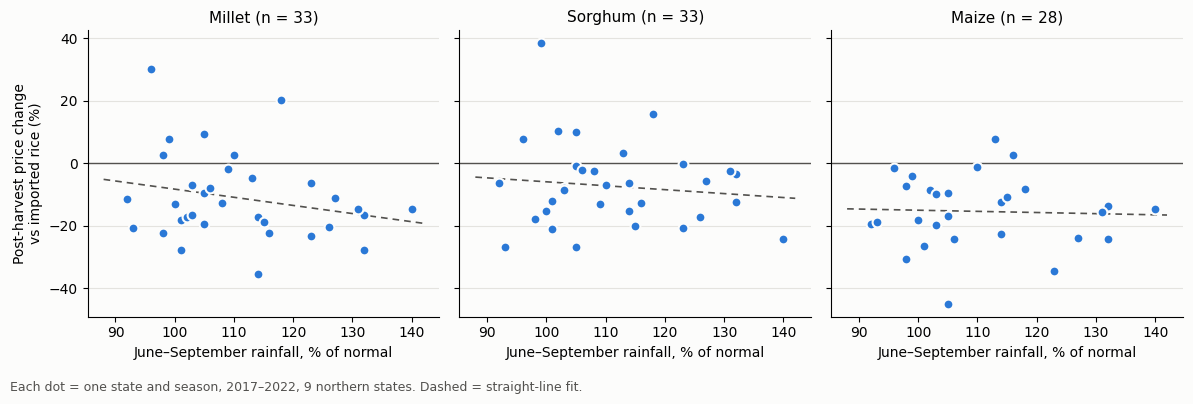

In [10]:
import matplotlib.pyplot as plt
BLUE, INK2, GRID, SURF = "#2a78d6", "#52514e", "#e4e3df", "#fcfcfb"
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, facecolor=SURF)
for ax, c in zip(axes, ["millet", "sorghum", "maize"]):
    g = loc[loc.crop == c]; y = (np.exp(g.rel_change) - 1) * 100
    ax.set_facecolor(SURF); ax.axhline(0, color=INK2, lw=1)
    ax.scatter(g.rain_pct, y, s=50, color=BLUE, edgecolor=SURF, linewidth=1.5, zorder=3)
    b = np.polyfit(g.rain_pct, y, 1); xs = np.array([88, 142])
    ax.plot(xs, np.polyval(b, xs), color=INK2, lw=1.2, ls=(0, (4, 3)))
    ax.set_title(f"{c.capitalize()} (n = {len(g)})", fontsize=11); ax.set_xlabel("June–September rainfall, % of normal")
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
axes[0].set_ylabel("Post-harvest price change\nvs imported rice (%)")
fig.text(0.01, 0.01, "Each dot = one state and season, 2017–2022, 9 northern states. Dashed = straight-line fit.", color=INK2, fontsize=9)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig("/kaggle/working/rain_vs_harvest_change.png", dpi=200, facecolor=SURF); plt.show()